In [1]:
# Журнал 
LOG_COLS = ["field", "issue", "scope", "n_rows", "value_before", "action", "value_after", "rationale"]
cleaning_log = []

def add_log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    cleaning_log.append(dict(zip(LOG_COLS, [field, issue, scope, n_rows, value_before, action, value_after, rationale])))


## 0. Зачитаем данные 

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

RAW_PATH = Path("..") / "data" / "raw" / "rent_v28.csv"
INTERIM_PATH = Path("..") / "data" / "interim" / "test.csv"

print(RAW_PATH.resolve(), "| файл найден:", RAW_PATH.exists())

df_naive = pd.read_csv(RAW_PATH, sep=";", encoding="cp1251", dtype={"id": "string"})

print(f"Размер: {df_naive.shape[0]} строк × {df_naive.shape[1]} столбцов")
df_naive.head(3)

C:\Users\6anna\PycharmProjects\Suhodolova_Anna_Lab2\data\raw\rent_v28.csv | файл найден: True
Размер: 12360 строк × 1 столбцов


,listing_id|publication_date|district|house_type|year_built|floors_total|floor|elevator|rooms|total_area|living_area|kitchen_area|ceiling_height|renovation|furniture|appliances|balcony|parking|metro_distance_m|distance_to_center_km|pets_allowed|seller_type|photos_count|response_time_hours|max_tenants|rent_rub
0,05d19173|2026-09-12|Первомайский|панельный|197...
1,1bcee754|2026-10-12|Центральный|кирпичный|1964...
2,9872d60f|2026-09-22|Заречный|панельный|1984|10...


Вывод: кодировку необходимо использовать "cp1251", а разделителями являются |
## 1. Минимальная подготовка данных до отделения test
### 1.1 Чтение данных с корректными типами

In [3]:
READ_KW = dict(sep="|", encoding="cp1251")

STR_COLS = ["listing_id"]
DATE_COLS = ["publication_date"]
CAT_COLS = ["district", "house_type", "elevator", "renovation", "furniture", "appliances", "balcony", "parking", "pets_allowed", "seller_type"]
INT_COLS = ["year_built", "floors_total", "floor", "rooms", "metro_distance_m", "photos_count", "max_tenants", "rent_rub"]
FLOAT_COLS = ["total_area", "living_area", "kitchen_area", "ceiling_height", "distance_to_center_km", "response_time_hours"]

# Читаем всё как текст: в числах есть пробелы и десятичная запятая
df = pd.read_csv(RAW_PATH, sep="|", encoding="cp1251", dtype=str, keep_default_na=False, na_values=[""])
print(f"Размер файла: {df.shape[0]} строк × {df.shape[1]} столбцов")

def to_num(s):
    clean = s.str.replace(r"[\s]", "", regex=True).str.replace(",", ".", regex=False)
    return pd.to_numeric(clean, errors="coerce")

df[STR_COLS] = df[STR_COLS].astype("string")
df[CAT_COLS] = df[CAT_COLS].astype("category")

# Дата: исходный текст сохраняем в s, чтобы найти значения, которые не удалось привести
s = df[DATE_COLS[0]]
df[DATE_COLS[0]] = pd.to_datetime(s, errors="coerce")
bad_dates = s.notna() & df[DATE_COLS[0]].isna()
print(f"{DATE_COLS[0]}: не приведено {bad_dates.sum()}, примеры: {s[bad_dates].unique()[:5]}")

for c in INT_COLS + FLOAT_COLS:
    s = df[c]
    df[c] = to_num(s)
    bad = s.notna() & df[c].isna()
    if bad.any():
        print(f"{c}: не приведено {bad.sum()} знач., примеры: {s[bad].unique()[:5]}")
    if c in INT_COLS:
        if (df[c].dropna() % 1 == 0).all():
            df[c] = df[c].astype("Int64")
        else:
            print(f"{c}: есть дробные значения, оставлен float64")

print(f"Размер: {df.shape[0]} строк × {df.shape[1]} столбцов")
df.head(3)

Размер файла: 12360 строк × 26 столбцов
publication_date: не приведено 0, примеры: []
Размер: 12360 строк × 26 столбцов


,listing_id,publication_date,district,house_type,year_built,floors_total,floor,elevator,rooms,total_area,...,balcony,parking,metro_distance_m,distance_to_center_km,pets_allowed,seller_type,photos_count,response_time_hours,max_tenants,rent_rub
0,05d19173,2026-09-12,Первомайский,панельный,1976,14,7,да,1,43.4,...,1,нет,320,6.9,нет,агентство,8,2.0,2,32000
1,1bcee754,2026-10-12,Центральный,кирпичный,1964,5,3,нет,3,59.4,...,1,открытая,290,2.6,нет,собственник,9,30.0,4,35000
2,9872d60f,2026-09-22,Заречный,панельный,1984,10,2,да,1,40.4,...,1,нет,1360,8.3,да,собственник,13,3.1,<NA>,25500


### 1.2 Проверка и удаление полных дубликатов 

In [4]:
# Полные дубликаты
dup_mask = df.duplicated(keep="first")
print("Полных дубликатов:", dup_mask.sum())
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))

n_before = len(df)
df = df[~dup_mask]
add_log("rent_v28*", "полные дубликаты строк", "вся выгрузка", int(dup_mask.sum()), f"{n_before} строк", "удалены, оставлен первый экземпляр", f"{len(df)} строк", "копия строки могла бы попасть и в train, и в test")
print(f"Строк: {n_before} -> {len(df)}")

Полных дубликатов: 180


,listing_id,publication_date,district,house_type,year_built,floors_total,floor,elevator,rooms,total_area,...,balcony,parking,metro_distance_m,distance_to_center_km,pets_allowed,seller_type,photos_count,response_time_hours,max_tenants,rent_rub
4614,02069026,2026-09-30,Ленинский,панельный,2011,25,3,да,2,47.5,...,2,нет,640,5.4,нет,собственник,9,0.7,4,40000
6031,02069026,2026-09-30,Ленинский,панельный,2011,25,3,да,2,47.5,...,2,нет,640,5.4,нет,собственник,9,0.7,4,40000
9840,027eccde,2026-09-28,Первомайский,панельный,1964,5,1,нет,3,50.8,...,1,нет,430,9.9,нет,собственник,5,9.1,5,20000
11421,027eccde,2026-09-28,Первомайский,панельный,1964,5,1,нет,3,50.8,...,1,нет,430,9.9,нет,собственник,5,9.1,5,20000
3450,02ef7f84,2026-09-20,Ленинский,панельный,1961,5,3,нет,3,50.6,...,1,нет,1690,6.6,нет,собственник,4,0.9,3,20500
4299,02ef7f84,2026-09-20,Ленинский,панельный,1961,5,3,нет,3,50.6,...,1,нет,1690,6.6,нет,собственник,4,0.9,3,20500
3731,046dd6f1,2026-10-04,Железнодорожный,монолитный,2025,9,1,да,0,21.5,...,1,нет,1160,7.3,нет,агентство,7,2.6,1,9000
5082,046dd6f1,2026-10-04,Железнодорожный,монолитный,2025,9,1,да,0,21.5,...,1,нет,1160,7.3,нет,агентство,7,2.6,1,9000
2836,0577a812,2026-09-24,Центральный,блочный,2005,10,7,да,4,100.9,...,1,нет,680,2.5,да,агентство,10,4.6,4,97000
3964,0577a812,2026-09-24,Центральный,блочный,2005,10,7,да,4,100.9,...,1,нет,680,2.5,да,агентство,10,4.6,4,97000


Строк: 12360 -> 12180


### 1.3 Удаляем строки без целевой переменной

In [5]:
# Строки без целевой переменной
empty_target = df["rent_rub"].isna()
print("Пустой rent_rub:", empty_target.sum())
display(df.loc[empty_target, ["listing_id", "rent_rub"]].head(10))

n_before = len(df)
df = df[~empty_target]

add_log("rent_rub", "пустое значение целевой переменной", "вся выгрузка", int(empty_target.sum()), f"{n_before} строк", "строки удалены", f"{len(df)} строк", "без цели нельзя ни обучить модель, ни посчитать метрики")
print(f"Строк: {n_before} -> {len(df)}")

Пустой rent_rub: 37


,listing_id,rent_rub
919,3fa182c8,<NA>
1496,f6590259,<NA>
1543,53c61df1,<NA>
1547,a38af5bd,<NA>
1927,4bf52500,<NA>
2495,59f93762,<NA>
3419,85217485,<NA>
3957,4fb33866,<NA>
4020,89551ae6,<NA>
4905,4471deb1,<NA>


Строк: 12180 -> 12143


Вывод: удалили все дубликаты и строки в которых не указана целевая переменная, теперь эти данные можно зарбивать на train, valid и est

## 2. Деление данных на test, validation и train
При разбиении выделим 15% на тест и 15% на валидацию, остальные 70% - train 

In [6]:
from sklearn.model_selection import train_test_split

# Задаём параметры разбиения (по 15% на валиданию и тест)
RANDOM_STATE = 42
TEST_SIZE, VALID_SIZE = 0.15, 0.15
INTERIM_PATH = Path("..") / "data" / "interim" / "test.csv"

# Разбиваем целевую переменную на 10 квантилей для стратификации
price_bins = pd.qcut(df["rent_rub"].astype(float), q=10, duplicates="drop")
# отделяем тестовую выборку (15%) от остальной части данных с сохранением распределения цен
dev_idx, test_idx = train_test_split(df.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=price_bins)
# делим оставшиеся 85% на train и valid
train_idx, valid_idx = train_test_split(dev_idx, test_size=VALID_SIZE / (1 - TEST_SIZE), random_state=RANDOM_STATE, stratify=price_bins.loc[dev_idx])

# Сохраняем выбранные строки в тест в изначальном виде в отдельном файле
raw = pd.read_csv(RAW_PATH, sep="|", encoding="cp1251", dtype=str, keep_default_na=False, na_values=[""])
INTERIM_PATH.parent.mkdir(parents=True, exist_ok=True)
raw.loc[test_idx.sort_values()].to_csv(INTERIM_PATH, sep="|", encoding="cp1251", index=False)

# Формируем итоговые датафреймы train, valid и test по полученным индексам
df_train, df_valid, df_test = df.loc[train_idx], df.loc[valid_idx], df.loc[test_idx]

# Выводим диагностику
test_check = pd.read_csv(INTERIM_PATH, sep="|", encoding="cp1251", dtype=str, keep_default_na=False, na_values=[""])
print(f"train {len(df_train)} | valid {len(df_valid)} | test {len(df_test)}")
print("Пересечений:", len(set(train_idx) & set(test_idx)), len(set(valid_idx) & set(test_idx)), len(set(train_idx) & set(valid_idx)))
print("Тест сохранён:", test_check.shape)

add_log("rent_v28*", "разбиение на выборки", "вся выгрузка", len(df), f"{len(df)} строк", f"train/valid/test, стратификация по децилям rent_rub, RANDOM_STATE={RANDOM_STATE}", f"{len(df_train)}/{len(df_valid)}/{len(df_test)}", "тест сохранён сырым в data/interim/, обучаемые параметры считаются только по train")

train 8499 | valid 1822 | test 1822
Пересечений: 0 0 0
Тест сохранён: (1822, 26)


Сравниваем выборки между собой.
- числовые признаки: медиана, доля пропусков, статистика KS 
- категории: частоты и доли
- Цена(целевая): ЭФР

,столбец,выборка,медиана train,медиана,KS,p,"пропуски train, %","пропуски, %"
3,floors_total,test,10.00,9.00,0.045,0.004,0.00,0.00
9,metro_distance_m,test,1310.00,1230.00,0.035,0.052,0.00,0.00
17,total_area,test,47.30,46.40,0.034,0.065,0.00,0.00
25,distance_to_center_km,test,7.10,6.90,0.031,0.108,0.00,0.00
24,distance_to_center_km,valid,7.10,6.90,0.029,0.152,0.00,0.00
20,kitchen_area,valid,8.50,8.40,0.029,0.175,7.24,7.52
1,year_built,test,1985.00,1985.00,0.027,0.254,9.52,10.04
19,living_area,test,26.40,26.00,0.025,0.335,6.00,5.49
23,ceiling_height,test,2.67,2.66,0.024,0.395,5.18,5.10
8,metro_distance_m,valid,1310.00,1240.00,0.024,0.327,0.00,0.00


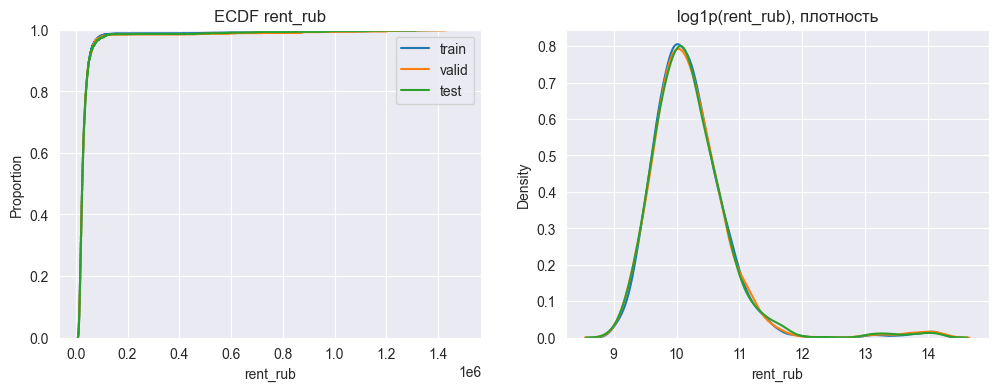

In [7]:
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# Сравниваем valid и test с train
parts = {"valid": df_valid, "test": df_test}

# Числовые признаки: сравниваем центр (медиану) и долю пропусков. (KS — максимальное расстояние между двумя ECDF(ЭФР) (долями наблюдений ≤ порога))
rows = []
for c in INT_COLS + FLOAT_COLS:
    a = df_train[c].dropna().astype(float)
    for name, part in parts.items():
        b = part[c].dropna().astype(float)
        ks = stats.ks_2samp(a, b)
        rows.append({"столбец": c, "выборка": name, "медиана train": a.median(), "медиана": b.median(), "KS": round(ks.statistic, 3), "p": round(ks.pvalue, 3), "пропуски train, %": round(df_train[c].isna().mean() * 100, 2), "пропуски, %": round(part[c].isna().mean() * 100, 2)})
num_cmp = pd.DataFrame(rows)
display(num_cmp.sort_values("KS", ascending=False).head(15))

# Целевая переменная: ECDF(ЭФР) показывает долю объявлений с ценой ≤ порога 
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, part in {"train": df_train, "valid": df_valid, "test": df_test}.items():
    sns.ecdfplot(part["rent_rub"].astype(float), ax=ax[0], label=name)
    sns.kdeplot(np.log1p(part["rent_rub"].astype(float)), ax=ax[1], label=name)
ax[0].set_title("ECDF rent_rub"); ax[1].set_title("log1p(rent_rub), плотность")
ax[0].legend()
plt.show()

Вывод: разбиение случайно, видно, что KS-статистика и доли малы, значит выборки сопоставимы. Распределение целевой переменной на всех трёх кусках данных совпадает.

## 3. Аудит
Аудит проводится только на train: его результаты определяют правила, которые записываются в Pipeline

In [8]:
import sys
sys.path.insert(0, str(Path("..").resolve()))

TARGET = "rent_rub"  # целевая
ID_COLS = ["listing_id"]
EXCLUDE = ["response_time_hours"]  # не используем инфа после публикации(утечка)
NUM_FEATURES = [c for c in INT_COLS + FLOAT_COLS if c not in [TARGET] + EXCLUDE] # Все численные категории
CAT_FEATURES = [c for c in CAT_COLS if c not in EXCLUDE] # Все использумые категории
FEATURES = NUM_FEATURES + CAT_FEATURES

# x — признаки, y — цель
X_train, y_train = df_train[FEATURES], df_train[TARGET].astype(float)
X_valid, y_valid = df_valid[FEATURES], df_valid[TARGET].astype(float)
num_train = X_train[NUM_FEATURES].astype(float)
print("Признаков:", len(FEATURES), "| числовых:", len(NUM_FEATURES), "| категориальных:", len(CAT_FEATURES))

Признаков: 22 | числовых: 12 | категориальных: 10


### 3.1 Паспорт данных

In [9]:
passport = pd.DataFrame({
    "тип": df_train.dtypes.astype(str),
    "пропусков": df_train.isna().sum(),
    "доля пропусков, %": (df_train.isna().mean() * 100).round(2),
    "уникальных": df_train.nunique(dropna=True),
})
display(passport)

print("\nКатегориальные столбцы: сколько раз встречается каждое значение")
for col in CAT_COLS:
    vc = df_train[col].value_counts(dropna=False)
    print(f"\n{col} (категорий: {df_train[col].nunique()}):")
    display(vc.to_frame("количество").assign(доля=lambda t: (t["количество"] / len(df_train) * 100).round(2)))

,тип,пропусков,"доля пропусков, %",уникальных
listing_id,string,0,0.00,8499
publication_date,datetime64[ns],0,0.00,61
district,category,40,0.47,12
house_type,category,0,0.00,5
year_built,Int64,809,9.52,106
floors_total,Int64,0,0.00,26
floor,Int64,0,0.00,27
elevator,category,0,0.00,2
rooms,Int64,0,0.00,6
total_area,float64,0,0.00,998



Категориальные столбцы: сколько раз встречается каждое значение

district (категорий: 12):


,количество,доля
district,,
Советский,900,10.59
Ленинский,838,9.86
Кировский,787,9.26
Заречный,777,9.14
Первомайский,734,8.64
Северный,685,8.06
Октябрьский,665,7.82
Железнодорожный,642,7.55
Центральный,636,7.48



house_type (категорий: 5):


,количество,доля
house_type,,
панельный,3789,44.58
кирпичный,2380,28.00
монолитный,1786,21.01
блочный,490,5.77
деревянный,54,0.64



elevator (категорий: 2):


... (11 outputs left out)


pets_allowed (категорий: 2):


,количество,доля
pets_allowed,,
нет,5533,65.1
да,2966,34.9



seller_type (категорий: 2):


,количество,доля
seller_type,,
собственник,5113,60.16
агентство,3386,39.84


### 3.2 Написание категорий

In [10]:
from difflib import SequenceMatcher
from modules.preprocessing import normalize_text, canon_key

for c in CAT_FEATURES:
    norm = normalize_text(X_train[c])  # пробелы по краям, регистр, повторные пробелы
    key = canon_key(X_train[c])        # ключ: без знаков, ё=е, латиница -> кириллица
    counts = norm.value_counts()       # частоты нормализованных написаний
    print(f"\n{c}: значений {X_train[c].nunique()} -> после нормализации {norm.nunique()} -> по ключу {key.nunique()}")

    # Написания, которые отличаются только знаками, ё/е или латиницей: ключ у них общий
    groups = pd.DataFrame({"norm": norm, "key": key}).dropna().groupby("key")["norm"].agg(lambda v: sorted(v.unique()))
    same = groups[groups.map(len) > 1]
    if len(same):
        display(same.to_frame("написания с одним ключом"))

    # Похожие, но с разными ключами: вероятные опечатки (решение принимаем вручную)
    vals = list(counts.index)
    keymap = dict(zip(vals, canon_key(pd.Series(vals))))
    similar = [(a, b, round(SequenceMatcher(None, a, b).ratio(), 2)) for i, a in enumerate(vals) for b in vals[i + 1:] if keymap[a] != keymap[b] and SequenceMatcher(None, a, b).ratio() >= 0.8]
    if similar:
        display(pd.DataFrame(similar, columns=["написание 1", "написание 2", "сходство"]).assign(частота_1=lambda t: t["написание 1"].map(counts), частота_2=lambda t: t["написание 2"].map(counts)))

    # Полная таблица только для столбцов с большим числом значений
    if norm.nunique() > 6:
        display(counts.to_frame("количество").assign(доля=lambda t: (t["количество"] / len(df_train) * 100).round(2)))


district: значений 12 -> после нормализации 12 -> по ключу 12


,количество,доля
district,,
советский,900,10.59
ленинский,838,9.86
кировский,787,9.26
заречный,777,9.14
первомайский,734,8.64
северный,685,8.06
октябрьский,665,7.82
железнодорожный,642,7.55
центральный,636,7.48



house_type: значений 5 -> после нормализации 5 -> по ключу 5

elevator: значений 2 -> после нормализации 2 -> по ключу 2

renovation: значений 20 -> после нормализации 14 -> по ключу 13


,написания с одним ключом
key,
евроремонт,"[евро-ремонт, евроремонт]"


,написание 1,написание 2,сходство,частота_1,частота_2
0,без ремонта,нет ремонта,0.82,1526,58


,количество,доля
renovation,,
косметический,3198,37.63
евроремонт,2036,23.96
без ремонта,1526,17.96
дизайнерский,714,8.4
косметика,169,1.99
косм.,139,1.64
евро,122,1.44
требует ремонта,96,1.13
евро-ремонт,79,0.93



furniture: значений 3 -> после нормализации 3 -> по ключу 3

appliances: значений 2 -> после нормализации 2 -> по ключу 2

balcony: значений 3 -> после нормализации 3 -> по ключу 3

parking: значений 3 -> после нормализации 3 -> по ключу 3

pets_allowed: значений 2 -> после нормализации 2 -> по ключу 2

seller_type: значений 2 -> после нормализации 2 -> по ключу 2


#### 3.2.1 Объединение названий категорий

In [11]:
from modules.preprocessing import CategoryCleaner

# Итоговые допустимые значения
VALID_CATEGORIES = {"renovation": ["евроремонт", "косметический", "без ремонта", "дизайнерский"]}

# Словари замен названий
CATEGORY_FIXES = {"renovation": {
    "косметика": "косметический",
    "косметический ремонт": "косметический",
    "дизайнерский ремонт": "дизайнерский",
    "нет ремонта": "без ремонта",     
    "требует ремонта": "без ремонта",
    "авторский": "дизайнерский",
}}

# Экземпляр "очистителя" обучаем на train
cleaner = CategoryCleaner(CAT_FEATURES, CATEGORY_FIXES, VALID_CATEGORIES).fit(X_train)
X_clean = cleaner.transform(X_train)  # новая таблица, X_train не изменился

display(X_clean["renovation"].value_counts(dropna=False).to_frame("количество"))
# Ищем знач не из VALID_CATEGORIES
left = X_clean["renovation"].value_counts().loc[lambda s: ~s.index.isin(VALID_CATEGORIES["renovation"])]
print("Неопознанные значения:"); display(left.to_frame("количество"))

add_log("renovation", "разные написания одной категории", "train, valid, test",
        int((X_train["renovation"].astype("string").str.strip().str.lower() != X_clean["renovation"]).sum()),
        "20 написаний", "нормализация + сопоставление с допустимыми + CATEGORY_FIXES",
        f"{X_clean['renovation'].nunique()} категорий", "OneHotEncoder не должен считать синонимы разными категориями")

,количество
renovation,
косметический,3549
евроремонт,2237
без ремонта,1680
дизайнерский,806
NaN,227


Неопознанные значения:


,количество
renovation,


### 3.3 Проверяем числовые признаки

In [12]:
checks = pd.Series({
    "kitchen_area | living_area | total_area < 0" : (df_train["living_area"]<0).sum() + (df_train["kitchen_area"]<0).sum() + (df_train["total_area"]<0).sum(),
    "floor < 1": (df_train["floor"] < 1).sum(),
    "floors_total < 1": (df_train["floors_total"] < 1).sum(),
    "floor > floors_total": (df_train["floor"] > df_train["floors_total"]).sum(),
    "living_area > total_area": (df_train["living_area"] > df_train["total_area"]).sum(),
    "kitchen_area > total_area": (df_train["kitchen_area"] > df_train["total_area"]).sum(),
    "living + kitchen > total": ((df_train["living_area"] + df_train["kitchen_area"]) > df_train["total_area"]).sum(),
    "year_built < 1800": (df_train["year_built"] < 1800).sum(),
    "year_built > 2026": (df_train["year_built"] > 2026).sum(),
    "площадь <= 0": (df_train[["total_area", "living_area", "kitchen_area"]] <= 0).any(axis=1).sum(),
    "metro_distance_m < 0": (df_train["metro_distance_m"] < 0).sum(),
    "distance_to_center_km > 50": (df_train["distance_to_center_km"] > 50).sum(),
    "rent_rub <= 0": (df_train[TARGET] <= 0).sum(),
})
display(checks.to_frame("строк"))
print("Диапазон дат:", df_train["publication_date"].min(), "—", df_train["publication_date"].max())

display(df_train.loc[df_train["distance_to_center_km"] > 50, ["distance_to_center_km", "district", "metro_distance_m"]].head(10))
display(df_train.loc[df_train["floors_total"] < 1, ["floors_total", "floor", "house_type", "year_built"]].head(10))
display(df_train.loc[df_train["living_area"] > df_train["total_area"], ["living_area", "kitchen_area", "total_area"]].head(10))


NUM_BOUNDS = {"floor": (1, None), "year_built": (1800, 2026), "total_area": (1, None), "living_area": (1, None), "kitchen_area": (1, None), "ceiling_height": (2, 6), "metro_distance_m": (0, None), "distance_to_center_km": (0, None)}
NUM_PAIRS = [("floor", "floors_total"), ("living_area", "total_area"), ("kitchen_area", "total_area")]

,строк
kitchen_area | living_area | total_area < 0,0
floor < 1,0
floors_total < 1,238
floor > floors_total,269
living_area > total_area,26
kitchen_area > total_area,0
living + kitchen > total,179
year_built < 1800,0
year_built > 2026,0
площадь <= 0,0


Диапазон дат: 2026-09-01 00:00:00 — 2026-10-31 00:00:00


,distance_to_center_km,district,metro_distance_m
9428,8800.0,Южный,7350
9773,8100.0,Кировский,480
9008,5400.0,Первомайский,1060
7060,12800.0,Северный,3980
10251,10800.0,Южный,4670
3261,6300.0,Заречный,1520
11779,3600.0,Октябрьский,1460
6679,7300.0,Советский,700
6810,3900.0,Октябрьский,540
400,1400.0,Центральный,850


,floors_total,floor,house_type,year_built
262,0,17,кирпичный,2016
4824,0,8,панельный,1979
5810,0,5,кирпичный,1985
1519,0,3,панельный,<NA>
685,0,1,кирпичный,1964
2650,0,14,панельный,1973
3499,0,2,кирпичный,<NA>
4298,0,13,монолитный,2019
5899,0,21,кирпичный,2019
10133,0,5,панельный,2016


,living_area,kitchen_area,total_area
7147,83.3,8.5,60.0
5213,104.7,10.5,93.5
7059,59.7,6.5,44.8
7710,55.8,7.7,50.8
1892,65.9,5.2,59.0
11069,84.5,7.0,76.2
8575,60.3,7.4,54.0
6283,93.5,8.7,68.3
1473,79.1,7.0,67.5
6101,66.3,9.4,50.0


#### 3.3.1 Числовая очистка

In [13]:
from modules.preprocessing import NumericCleaner

# проверяем очистку на отдельной копии train
num_cleaner = NumericCleaner(NUM_FEATURES, NUM_BOUNDS, NUM_PAIRS)
X_num_clean = num_cleaner.fit_transform(X_train)

# Маски считаем по данным ДО очистки
meters_mask = X_train["distance_to_center_km"] > 50
zero_floors_mask = X_train["floors_total"] == 0

# Все расстояния, которые изменятся, и результат деления
display(pd.DataFrame({
        "было": X_train.loc[meters_mask, "distance_to_center_km"],
        "стало, км": X_num_clean.loc[meters_mask, "distance_to_center_km"],
    }).sort_values("было"))

# Проверяем новые пропуски в числовых признаках
new_na = X_train[NUM_FEATURES].notna() & X_num_clean[NUM_FEATURES].isna()
display(new_na.sum().loc[lambda s: s > 0].to_frame("новых пропусков"))

# Показываем площади после применения правил
area_mask = X_train["living_area"] > X_train["total_area"]
display(X_num_clean.loc[ area_mask, ["living_area", "kitchen_area", "total_area"]].head(10))

# объединяем обе очистки в одной таблице
X_clean = cleaner.transform(X_num_clean)

,было,"стало, км"
3510,400.0,0.4
11458,500.0,0.5
3118,900.0,0.9
400,1400.0,1.4
11634,1500.0,1.5
...,...,...
8888,14100.0,14.1
3941,15000.0,15.0
5007,15200.0,15.2
4739,15400.0,15.4


,новых пропусков
floors_total,238
floor,31
living_area,180
kitchen_area,154


,living_area,kitchen_area,total_area
7147,NaN,8.5,60.0
5213,NaN,10.5,93.5
7059,NaN,6.5,44.8
7710,NaN,7.7,50.8
1892,NaN,5.2,59.0
11069,NaN,7.0,76.2
8575,NaN,7.4,54.0
6283,NaN,8.7,68.3
1473,NaN,7.0,67.5
6101,NaN,9.4,50.0


#### 3.3.2 Записываем решения в журнал

In [14]:
# фиксируем принятое правило перевода единиц
add_log("distance_to_center_km", "предполагаемое смешение метров и километров", "train", int(meters_mask.sum()), "значения > 50", "деление на 1000 внутри NumericCleaner", "расстояние в километрах", "принята гипотеза: значения > 50 записаны в метрах; проверяется по таблице до/после")

# ноль -> неизвестная этажность
add_log("floors_total", "нулевая этажность", "train", int(zero_floors_mask.sum()), "0", "замена на NaN внутри NumericCleaner", "пропуск", "нулевая этажность трактуется как неизвестная; строки и остальные признаки сохраняются")

# фиксируем новые пропуски от остальных числовых правил
for c in NUM_FEATURES:
    mask = new_na[c].copy()
    # Нулевую этажность уже записали отдельно
    if c == "floors_total":
        mask &= ~zero_floors_mask.fillna(False)

    n = int(mask.sum())
    if n:
        add_log(c, "нарушение допустимого диапазона или отношения признаков", "train", n, str(X_train.loc[mask, c].head(5).tolist()), "замена на NaN внутри NumericCleaner",  "пропуск",  "правила NUM_BOUNDS и NUM_PAIRS; в паре сохраняем опорное поле, недопустимое зависимое значение считаем неизвестным")

# отдельная неоднозначность: пока без автоматической замены
area_sum_mask = ((X_train["living_area"] <= X_train["total_area"])
               & (X_train["kitchen_area"] <= X_train["total_area"])
               & (X_train["living_area"] + X_train["kitchen_area"]> X_train["total_area"]))

add_log("living_area + kitchen_area", "сумма площадей больше общей после остальных проверок", "train", int(area_sum_mask.sum()),  "living_area + kitchen_area > total_area", "living_area и kitchen_area заменены на NaN", "общая площадь сохранена", "невозможно надёжно определить ошибочную составляющую; обе составляющие считаем неизвестными")


### 3.4 Проверяем результаты

In [15]:
# общий результат очистки
missing = pd.DataFrame({
    "пропусков до": X_train.isna().sum(),
    "новых пропусков": (X_train.notna() & X_clean.isna()).sum(),
    "пропусков после": X_clean.isna().sum(),
})
display(missing)

checks_after = pd.Series({
    "floors_total == 0": (X_clean["floors_total"] == 0).sum(),
    "floor > floors_total": (X_clean["floor"] > X_clean["floors_total"]).sum(),
    "living_area > total_area": (X_clean["living_area"] > X_clean["total_area"]).sum(),
    "kitchen_area > total_area": (X_clean["kitchen_area"] > X_clean["total_area"]).sum(),
    "living + kitchen > total": ((X_clean["living_area"] + X_clean["kitchen_area"]) > X_clean["total_area"]).sum(),
    "distance_to_center_km > 50": (X_clean["distance_to_center_km"] > 50).sum(),
})
display(checks_after.to_frame("нарушений после очистки"))
print("Строк до / после:", len(X_train), "/", len(X_clean))
# Если один из участников пары неизвестен, сравнить их нельзя
print("Неизвестная этажность:", X_clean["floors_total"].isna().sum())
print("Неизвестная жилая площадь:", X_clean["living_area"].isna().sum())

display(X_train.loc[X_clean["living_area"]+X_clean["kitchen_area"]  > X_clean["total_area"], ["living_area", "kitchen_area", "total_area"]].head(10))

,пропусков до,новых пропусков,пропусков после
year_built,809,0,809
floors_total,0,238,238
floor,0,31,31
rooms,0,0,0
metro_distance_m,0,0,0
photos_count,155,0,155
max_tenants,151,0,151
total_area,0,0,0
living_area,510,180,690
kitchen_area,615,154,769


,нарушений после очистки
floors_total == 0,0
floor > floors_total,0
living_area > total_area,0
kitchen_area > total_area,0
living + kitchen > total,0
distance_to_center_km > 50,0


Строк до / после: 8499 / 8499
Неизвестная этажность: 238
Неизвестная жилая площадь: 690


,living_area,kitchen_area,total_area


Вывод: после очистки нарушений нет

### 3.5 Распределения числовых признаков


,известно,min,25%,медиана,75%,max,асимметрия
year_built,7690,1920.0,1970.00,1985.00,2011.00,2025.00,-0.31
floors_total,8261,1.0,5.00,10.00,14.00,25.00,0.58
floor,8468,1.0,3.00,5.00,8.00,25.00,1.24
rooms,8499,0.0,1.00,2.00,2.00,5.00,0.42
metro_distance_m,8499,80.0,690.00,1310.00,4480.00,9000.00,1.05
photos_count,8344,0.0,6.00,8.00,12.00,28.00,0.53
max_tenants,8348,1.0,2.00,3.00,4.00,7.00,0.36
total_area,8499,15.7,36.20,47.30,62.10,171.60,1.32
living_area,7809,10.7,20.60,26.50,35.60,107.50,1.47
kitchen_area,7730,4.0,6.70,8.50,10.60,23.70,0.98


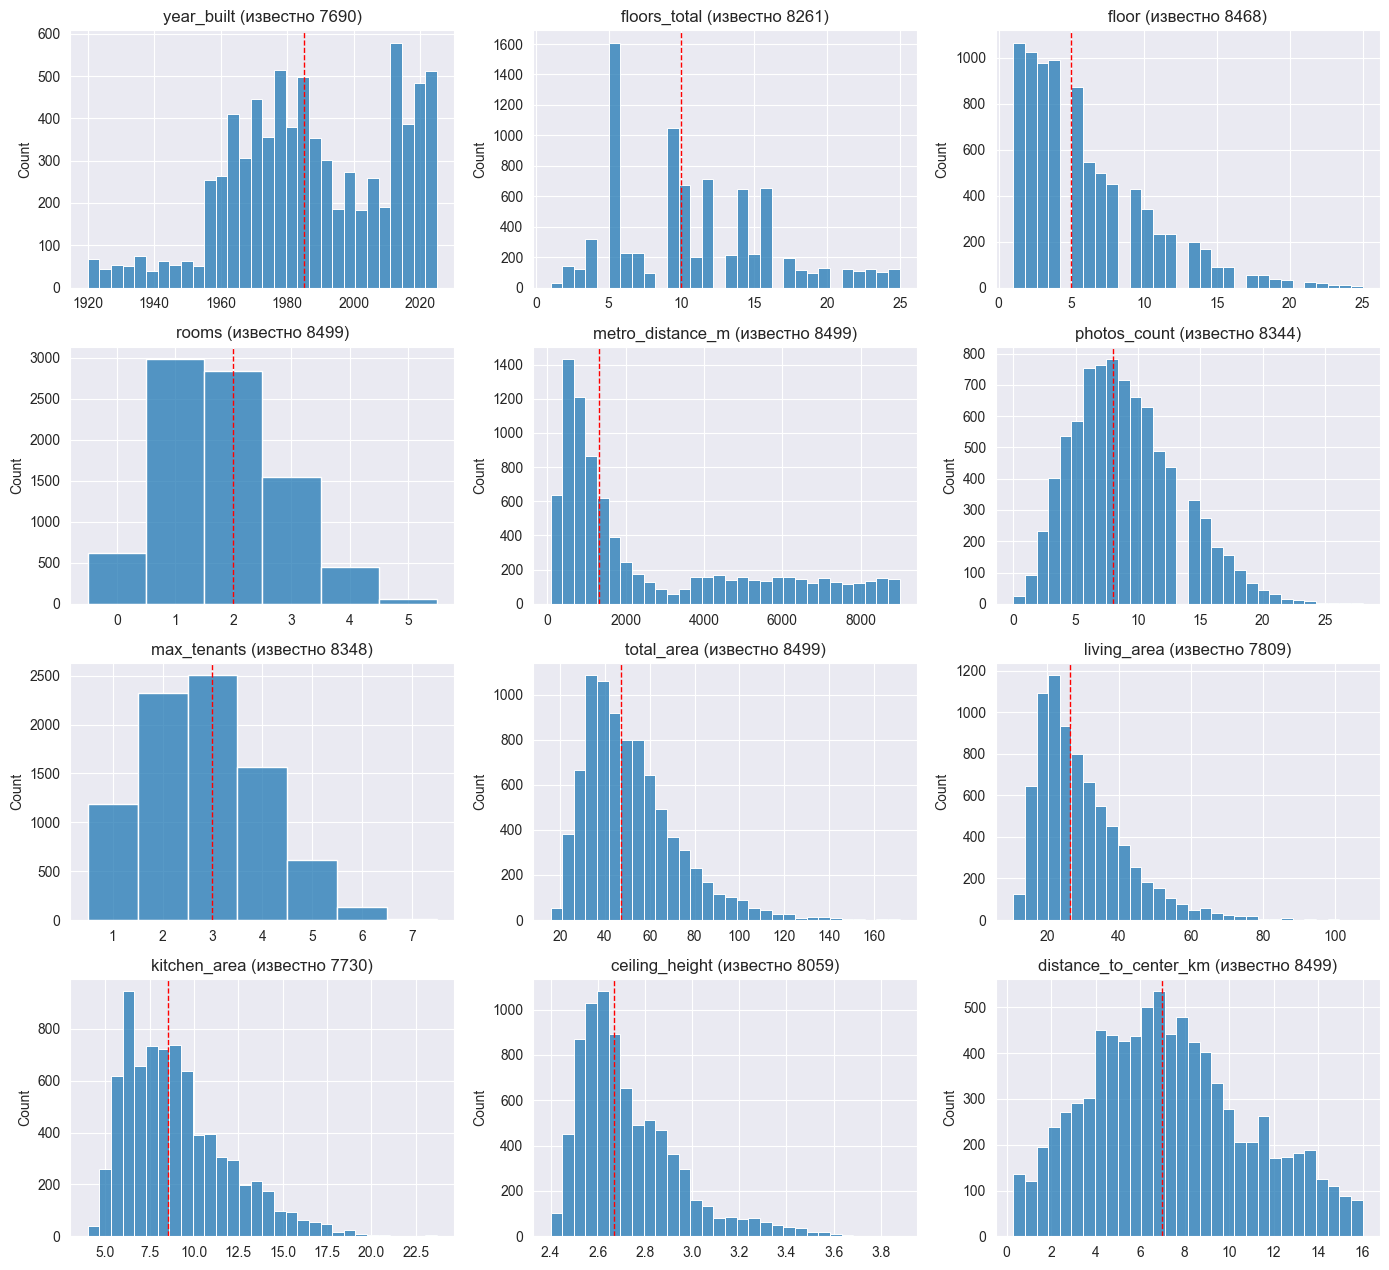

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Только известные значения после очистки (пропуски пока не заполняем)
num_clean = X_clean[NUM_FEATURES].astype(float)

# Таблица: сколько значений известно и как устроено распределение
dist = pd.DataFrame({
    "известно": num_clean.notna().sum(),
    "min": num_clean.min(),
    "25%": num_clean.quantile(0.25),
    "медиана": num_clean.median(),
    "75%": num_clean.quantile(0.75),
    "max": num_clean.max(),
    "асимметрия": num_clean.skew(),   # > 0 — правый хвост, < 0 — левый
})
display(dist.round(2))

# Признаки с малым числом значений рисуем столбцами по значениям
DISCRETE = ["rooms", "max_tenants"]

n_cols = 3
n_rows = int(np.ceil(len(NUM_FEATURES) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.2 * n_rows))
axes = axes.ravel()

for ax, c in zip(axes, NUM_FEATURES):
    data = num_clean[c].dropna()
    sns.histplot(data, bins=30, discrete=(c in DISCRETE), ax=ax)
    ax.axvline(data.median(), color="red", linestyle="--", linewidth=1)  # красная линия — медиана
    ax.set_title(f"{c} (известно {len(data)})")
    ax.set_xlabel("")

# Пустые ячейки сетки скрываем
for ax in axes[len(NUM_FEATURES):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Вывод:
- total_area, living_area, kitchen_area — правосторонняя асимметрия (много маленьких квартир, хвост вправо).
- rooms, max_tenants — дискретные.
- ceiling_height — явный пик на ~2.6 (стандарт).
- metro_distance_m — бимодальное (или с длинным хвостом).

### 3.6 Распределение целевой переменной и её связь с остальными числовыми признаками

,Spearman с rent_rub
total_area,0.693
living_area,0.665
rooms,0.567
max_tenants,0.465
distance_to_center_km,-0.461
ceiling_height,0.397
kitchen_area,0.387
metro_distance_m,-0.295
photos_count,0.223
year_built,0.143


,count,median
district,,
Промышленный,605,18000.0
Северный,685,20000.0
Южный,566,20000.0
Железнодорожный,642,20500.0
Лесной,624,21500.0
Первомайский,734,23000.0
Кировский,787,25000.0
Заречный,777,26000.0
Советский,900,26500.0


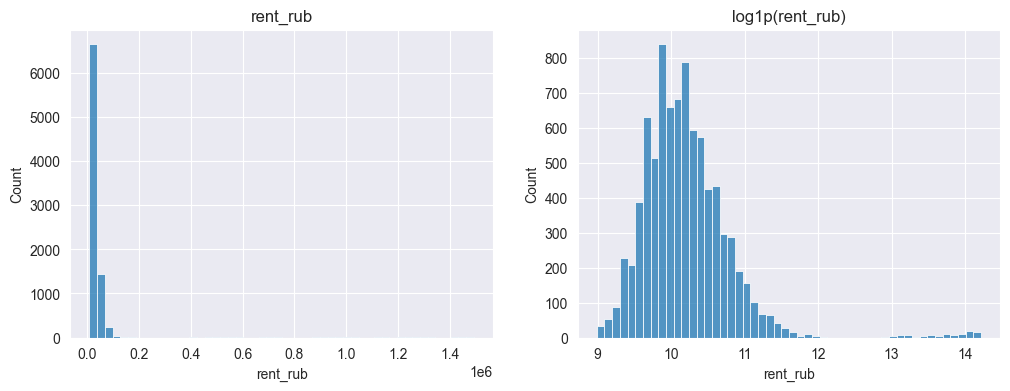

In [17]:
# анализируем уже очищенные числа
num_train = X_clean[NUM_FEATURES].astype(float)
display(num_train.corrwith(y_train, method="spearman").sort_values(key=abs, ascending=False).round(3).to_frame("Spearman с rent_rub"))
display(df_train.groupby("district", observed=True)[TARGET].agg(["count", "median"]).sort_values("median"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_train, bins=50, ax=ax[0])
sns.histplot(np.log1p(y_train), bins=50, ax=ax[1])
ax[0].set_title("rent_rub")
ax[1].set_title("log1p(rent_rub)")
plt.show()

Вывод: 
- сильная правая асимметрия, при log приближается к нормальному распределению
- Спирмен с rent_rub: самые сильные монотонные связи - total_area, living_area и rooms

## 4. Анализ и обработка пропусков
### 4.1 Подготовка данных для анализа пропусков
Применяем только категориальную и числовую очистку

In [18]:
from modules.preprocessing import NumericCleaner, CategoryCleaner

# Параметры и правила берём из главы 3
num_cleaner = NumericCleaner(NUM_FEATURES, NUM_BOUNDS, NUM_PAIRS)
cleaner = CategoryCleaner(CAT_FEATURES, CATEGORY_FIXES, VALID_CATEGORIES)

X_num_clean = num_cleaner.fit_transform(X_train)
X_clean = cleaner.fit_transform(X_num_clean)

# Validation: только transform, без обучения новых соответствий
X_valid_clean = num_cleaner.transform(X_valid)
X_valid_clean = cleaner.transform(X_valid_clean)

print("Строк train:", len(X_clean))
print("Строк valid:", len(X_valid_clean))

Строк train: 8499
Строк valid: 1822


### 4.2 Сколько пропусков и происхождение

In [19]:
missing = pd.DataFrame({
    "до очистки": X_train.isna().sum(),
    "добавлено очисткой": (X_train.notna() & X_clean.isna()).sum(),
    "после очистки": X_clean.isna().sum(),
    "после, %": (X_clean.isna().mean() * 100).round(2),
})
display(missing.sort_values("после очистки", ascending=False))

print("Строк хотя бы с одним пропуском:", X_clean.isna().any(axis=1).sum())
print("Полных строк:", X_clean.notna().all(axis=1).sum())
print("Потеряли бы при dropna, %:", round(X_clean.isna().any(axis=1).mean() * 100, 2))

# Проверяем, нет ли столбца, который полностью пуст
print("Полностью пустые столбцы:", X_clean.columns[X_clean.isna().all()].tolist())

# Сколько пропусков приходится на одну строку
display(X_clean.isna().sum(axis=1).value_counts().sort_index().to_frame("число объявлений"))


,до очистки,добавлено очисткой,после очистки,"после, %"
year_built,809,0,809,9.52
kitchen_area,615,154,769,9.05
living_area,510,180,690,8.12
ceiling_height,440,0,440,5.18
balcony,357,0,357,4.20
parking,263,0,263,3.09
floors_total,0,238,238,2.80
renovation,227,0,227,2.67
furniture,227,0,227,2.67
photos_count,155,0,155,1.82


Строк хотя бы с одним пропуском: 3452
Полных строк: 5047
Потеряли бы при dropna, %: 40.62
Полностью пустые столбцы: []


,число объявлений
0,5047
1,2632
2,706
3,103
4,11


Вывод: если удалять все строки с пропусками, то потеряем 40% выборки - не подходит. Нужно изучить: есть ли закономерности(связь) между признаками и целевой переменной

## 4.3 Пропуски и стоимость аренды
Посмотрим есть ли явная связь между значением целевой переменной и пропусками в разных признаках

In [20]:
missing_cols = missing.index[missing["после очистки"] > 0].tolist()

for c in missing_cols:
    temp = pd.DataFrame({ "есть пропуск": X_clean[c].isna(), "rent_rub": y_train,})
    
    # Считаем метрики
    stats = temp.groupby("есть пропуск")["rent_rub"].agg(["count", "median", "mean"]).round(2)
    quantiles = temp.groupby("есть пропуск")["rent_rub"].quantile([0.25, 0.75]).unstack().round(2)
    
    # Объединяем в одну таблицу
    combined_table = pd.concat([stats, quantiles], axis=1)
    
    print(f"\n{c} | False — известно, True — пропуск")
    display(combined_table)


year_built | False — известно, True — пропуск


,count,median,mean,0.25,0.75
есть пропуск,,,,,
False,7690,25000.0,40688.1,18500.0,35500.0
True,809,25500.0,41640.3,17500.0,37500.0



floors_total | False — известно, True — пропуск


,count,median,mean,0.25,0.75
есть пропуск,,,,,
False,8261,25000.0,40936.02,18000.0,35500.0
True,238,26000.0,35319.33,19125.0,36375.0



floor | False — известно, True — пропуск


,count,median,mean,0.25,0.75
есть пропуск,,,,,
False,8468,25000.0,40670.47,18000.0,35500.0
True,31,25500.0,70354.84,16250.0,35750.0


... (16 outputs left out)


balcony | False — известно, True — пропуск


,count,median,mean,0.25,0.75
есть пропуск,,,,,
False,8142,25000.0,40540.84,18000.0,35500.0
True,357,26000.0,46204.48,18500.0,36000.0



parking | False — известно, True — пропуск


,count,median,mean,0.25,0.75
есть пропуск,,,,,
False,8236,25000.0,40731.73,18000.0,35500.0
True,263,25000.0,42250.95,18250.0,35000.0


Вывод: 
- самая сильная закономерность(связь) в площади кухни, если не указана площадь кухни цена сильно снижается(по медиане) относительно квартир, где площадь кухни указана. 
- ceiling_height, balcony, furniture — при пропуске цена чуть выше по среднему, а по медиане различий практически нет.
- photos_count, district — при пропуске цена ниже.

## 4.4 Связи числовых признаков

In [21]:
# Связи с целевой переменной и между признаками
num_train = X_clean[NUM_FEATURES].astype(float)

display(num_train.corrwith(y_train, method="spearman")
        .sort_values(key=abs, ascending=False).round(3)
        .to_frame("Spearman с rent_rub"))

corr = num_train.corr(method="spearman")
rows = []
for i, a in enumerate(NUM_FEATURES):
    for b in NUM_FEATURES[i + 1:]:
        if abs(corr.loc[a, b]) >= 0.8:
            rows.append({"признак 1": a, "признак 2": b, "Spearman": round(corr.loc[a, b], 3), "известны оба": int(num_train[[a, b]].notna().all(axis=1).sum()),})
display(pd.DataFrame(rows, columns=["признак 1", "признак 2", "Spearman", "известны оба"]))

,Spearman с rent_rub
total_area,0.693
living_area,0.665
rooms,0.567
max_tenants,0.465
distance_to_center_km,-0.461
ceiling_height,0.397
kitchen_area,0.387
metro_distance_m,-0.295
photos_count,0.223
year_built,0.143


,признак 1,признак 2,Spearman,известны оба
0,rooms,max_tenants,0.805,8348
1,rooms,total_area,0.888,8499
2,rooms,living_area,0.827,7809
3,total_area,living_area,0.942,7809


Вывод: признаки rooms, максимальное число жильцов и площади имеют сильную связь, поэтому их потом надо проверить на мультиколлинеарность и возможно вывести из них новые признаки, например, оставить только доли площадей.
Решение: рассчитать VIF для диагностики мультиколлинеарности

### 4.5 Анализ исходных пропусков кухни

In [22]:
# Маски строим до заполнения
kitchen_original_missing = X_train["kitchen_area"].isna()
kitchen_added_missing = X_train["kitchen_area"].notna() & X_clean["kitchen_area"].isna()

print("Исходных пропусков кухни:", kitchen_original_missing.sum())
print("Добавлено очисткой:", kitchen_added_missing.sum())
print("Число квартир с нулевым количеством комнат: ", (X_clean["rooms"]==0).sum())

# Гипотезу об исходных пропусках проверяем отдельно
kitchen_analysis = pd.DataFrame({
    "rooms": X_clean["rooms"],
    "исходный пропуск кухни": kitchen_original_missing,
    "total_area": X_clean["total_area"],
})
display(kitchen_analysis.groupby("rooms").agg(объявлений=("исходный пропуск кухни", "size"), исходных_пропусков=("исходный пропуск кухни", "sum"), доля_пропусков=("исходный пропуск кухни", "mean")).assign(доля_пропусков=lambda t: (t["доля_пропусков"] * 100).round(2)))

# Сравниваем три группы, не смешивая причины неизвестности
status = pd.Series("известна после очистки", index=X_clean.index)
status.loc[kitchen_original_missing] = "исходный пропуск"
status.loc[kitchen_added_missing] = "добавлено очисткой"
kitchen_groups = pd.DataFrame({"статус кухни": status, "total_area": X_clean["total_area"]})
display(kitchen_groups.groupby("статус кухни")["total_area"].agg(["count", "median", "mean"]).round(2))

Исходных пропусков кухни: 615
Добавлено очисткой: 154
Число квартир с нулевым количеством комнат:  615


,объявлений,исходных_пропусков,доля_пропусков
rooms,,,
0.0,615,615,100.0
1.0,2988,0,0.0
2.0,2844,0,0.0
3.0,1548,0,0.0
4.0,448,0,0.0
5.0,56,0,0.0


,count,median,mean
статус кухни,,,
добавлено очисткой,154,34.6,35.52
известна после очистки,7730,49.7,54.00
исходный пропуск,615,25.6,25.98


Вывод: : пропуски в площади кухни встречаются исключительно при rooms == 0. Это означает, что такие объекты — студии без выделенной кухни

Решение: 
Для студий (rooms == 0): заполняем пропуск площади кухни нулем и создаем бинарный флаг


#### 4.5.1 Заполняем часть пропусков кухни нулями
Зафиксированным правилом в KitchenZeroFiller

In [23]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from modules.preprocessing import NumericCleaner, CategoryCleaner, KitchenZeroFiller

# Только очистка и технические нули; доли площадей не рассчитываем
area_pipeline = Pipeline([
    ("numeric_cleaner", NumericCleaner(NUM_FEATURES, NUM_BOUNDS, NUM_PAIRS)),
    ("category_cleaner", CategoryCleaner(CAT_FEATURES, CATEGORY_FIXES, VALID_CATEGORIES)),
    ("kitchen_zero", KitchenZeroFiller()),
])

X_zero = area_pipeline.fit_transform(X_train)
X_valid_zero = area_pipeline.transform(X_valid)

# Состояние до подстановки нулей
X_before_zero = area_pipeline[:-1].transform(X_train)
X_valid_before_zero = area_pipeline[:-1].transform(X_valid)


### 4.6 Проверим 5 признаков на мультиколлинеарность
### 4.6.1 Проверим корреляции 5 признаков 

In [24]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# 
# COLLINEAR_FEATURES = ["rooms", "max_tenants", "total_area", "living_area", "kitchen_area"]
# 
# # Данные до и после технического кодирования кухни
# X_corr = X_before_zero[COLLINEAR_FEATURES].astype(float)
# X_corr_zero = X_zero[COLLINEAR_FEATURES].astype(float)
# 
# # Сколько наблюдений использовано для каждой пары
# known = X_corr.notna().astype(int)
# display((known.T @ known).rename_axis("совместно известны"))
# 
# # Pearson — линейные связи, Spearman — монотонные
# fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# for ax, data, method, title in [
#     (axes[0], X_corr, "pearson", "Pearson: до технических нулей"),
#     (axes[1], X_corr, "spearman", "Spearman: до технических нулей"),
#     (axes[2], X_corr_zero, "pearson", "Pearson: с техническими нулями"),
# ]:
#     sns.heatmap(data.corr(method=method), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
#     ax.set_title(title)
# plt.tight_layout()
# plt.show()
# 
# # Сводка сильных пар без автоматического удаления
# pearson = X_corr.corr(method="pearson")
# spearman = X_corr.corr(method="spearman")
# rows = []
# for i, a in enumerate(COLLINEAR_FEATURES):
#     for b in COLLINEAR_FEATURES[i + 1:]:
#         if max(abs(pearson.loc[a, b]), abs(spearman.loc[a, b])) >= 0.8:
#             rows.append([a, b, pearson.loc[a, b], spearman.loc[a, b], int(X_corr[[a, b]].notna().all(axis=1).sum())])
# 
# display(pd.DataFrame(rows, columns=["признак 1", "признак 2", "Pearson", "Spearman", "наблюдений"]).round(3))

### 4.6.2 VIF и поочерёдное исключение

In [25]:
# from statsmodels.tools.tools import add_constant
# from statsmodels.stats.outliers_influence import variance_inflation_factor
# 
# # Фиксированная подвыборка без заполнения площадей
# X_vif = X_corr.dropna().copy()
# print(f"Для VIF: {len(X_vif)} из {len(X_corr)} строк ({len(X_vif) / len(X_corr):.1%})")
# 
# # Проверяем, какие квартиры вошли в расчёт
# display(pd.crosstab(X_before_zero["rooms"], X_corr.notna().all(axis=1)).rename(columns={False: "не вошли", True: "вошли"}))
# 
# def calculate_vif(data):
#     # Постоянные столбцы не дают полезного VIF
#     if len(data) <= data.shape[1] + 1:
#         raise ValueError("Недостаточно полных строк для VIF.")
#     if data.nunique().le(1).any():
#         raise ValueError(f"Постоянные столбцы: {data.columns[data.nunique().le(1)].tolist()}")
# 
#     matrix = add_constant(data.astype(float), has_constant="add")
#     values = [variance_inflation_factor(matrix.to_numpy(), i) for i in range(1, matrix.shape[1])]
#     return pd.Series(values, index=data.columns, name="VIF").sort_values(ascending=False)
# 
# # Базовый VIF и пересчёт после исключения каждого признака
# vif_tables = {"все пять": calculate_vif(X_vif)}
# for col in COLLINEAR_FEATURES:
#     vif_tables[f"без {col}"] = calculate_vif(X_vif.drop(columns=col))
# 
# display(pd.concat(vif_tables, axis=1).round(2))

Вывод: на подвыборке с полностью известными 5 исследуемыми признаками максимальная избыточность у общей и жилой площадей. Нужно попробовать создать новые признаки на основе этих

### 4.6.3 Кандидаты новых признаков

In [26]:
# def make_area_features(X):
#     X = X[COLLINEAR_FEATURES].astype(float).copy()
# 
#     # Делим только на известные положительные значения
#     total = X["total_area"].where(X["total_area"].gt(0))
#     tenants = X["max_tenants"].where(X["max_tenants"].gt(0))
# 
#     X["living_share"] = X["living_area"] / total
#     X["kitchen_share"] = X["kitchen_area"] / total
#     X["area_per_tenant"] = X["total_area"] / tenants
# 
#     # Отрицательный остаток не считаем корректным признаком площади
#     remainder = X["total_area"] - X["living_area"]
#     X["nonliving_area"] = remainder.where(remainder.ge(0))
#     return X
# 
# # Физические доли рассчитываем до технических нулей
# X_candidates = make_area_features(X_before_zero)
# X_valid_candidates = make_area_features(X_valid_before_zero)
# 
# # Для варианта с абсолютной кухней сохраняем выбранное кодирование нулём
# X_candidates["kitchen_area"] = X_zero["kitchen_area"].astype(float)
# X_valid_candidates["kitchen_area"] = X_valid_zero["kitchen_area"].astype(float)
# 
# feature_sets = {"все пять": COLLINEAR_FEATURES.copy()}
# 
# # Проверяем удаление каждого признака, включая total_area
# for col in COLLINEAR_FEATURES:
#     feature_sets[f"без {col}"] = [c for c in COLLINEAR_FEATURES if c != col]
# 
# feature_sets.update({
#     "площадь и комнаты": ["total_area", "rooms"],
#     "размер и доли": ["total_area", "rooms", "living_share", "kitchen_share"],
#     "площадь и нежилая часть": ["total_area", "rooms", "nonliving_area"],
#     "площадь на жильца": ["total_area", "rooms", "living_area", "kitchen_area", "area_per_tenant"],
# })
# 
# display(pd.Series(feature_sets, name="признаки").to_frame())

### 4.6.4 Проверим модели на разных признаках

In [27]:
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import StandardScaler
# from sklearn.linear_model import LinearRegression, Ridge
# from sklearn.model_selection import KFold, cross_validate
# 
# # Все варианты используют одинаковые разбиения train
# cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}
# models = {"LinearRegression": LinearRegression(), "Ridge": Ridge(alpha=10)}
# results = []
# 
# for model_name, model in models.items():
#     for set_name, cols in feature_sets.items():
#         # Импьютер и scaler обучаются заново внутри каждого фолда
#         pipe = Pipeline([
#             ("imputer", SimpleImputer(strategy="median")),
#             ("scaler", StandardScaler()),
#             ("model", model),
#         ])
#         scores = cross_validate(pipe, X_candidates[cols], y_train, cv=cv, scoring=scoring, error_score="raise")
#         mae = -scores["test_MAE"]
#         rmse = -scores["test_RMSE"]
#         results.append([model_name, set_name, len(cols), mae.mean(), mae.std(), rmse.mean(), rmse.std()])
# 
# results = pd.DataFrame(results, columns=["модель", "набор", "признаков", "MAE", "MAE std", "RMSE", "RMSE std"])
# 
# # Разница относительно всех пяти признаков для каждой модели
# baseline_mae = results.loc[results["набор"].eq("все пять")].set_index("модель")["MAE"]
# results["ΔMAE к пяти"] = results["MAE"] - results["модель"].map(baseline_mae)
# 
# display(results.sort_values(["модель", "MAE"]).round(2))

Вывод: улучшение прогноза в среднем на 2 рубля не даёт веских оснований удалять признак max_tenants пока. А остальные варианты дают только ухудшение прогноза.
Решение: пока оставляем все 5 признаков

#### 4.6.5 Заполним площади медианными долями

In [28]:
# from sklearn.pipeline import Pipeline
# from modules.preprocessing import AreaShareImputer
# 
# # Добавляем заполнение площадей после технических нулей кухни
# filled_pipeline = Pipeline(area_pipeline.steps + [("area_shares", AreaShareImputer())])
# 
# X_filled = filled_pipeline.fit_transform(X_train)
# X_valid_filled = filled_pipeline.transform(X_valid)
# 
# # Состояние до расчётного заполнения понадобится для анализа жильцов
# X_before_shares = filled_pipeline[:-1].transform(X_train)
# 
# area_filler = filled_pipeline.named_steps["area_shares"]
# print("Медианная доля жилой площади:", round(area_filler.living_share_, 3))
# print("Медианная доля кухни:", round(area_filler.kitchen_share_, 3))
# 
# # Показываем результат, не меняя известные площади
# cols = ["total_area", "living_area", "kitchen_area"]
# display(pd.DataFrame({"до": X_before_shares[cols].isna().sum(), "после": X_filled[cols].isna().sum()}))
# 
# mask = X_before_shares["living_area"].isna() | X_before_shares["kitchen_area"].isna()
# display(X_filled.loc[mask, cols + ["living_area_missing", "kitchen_area_missing"]].head(10))

#### 4.6.6 Площади квартир по максимальному числу жильцов

In [29]:
# # Берём площади до заполнения долями
# tenants_data = X_before_shares[["max_tenants", "total_area", "living_area", "kitchen_area"]].astype(float).copy()
# tenants_data = tenants_data.loc[tenants_data["max_tenants"].notna()]
# 
# # Технический ноль не является измеренной площадью кухни
# tenants_data["kitchen_area"] = tenants_data["kitchen_area"].where(tenants_data["kitchen_area"].gt(0))
# 
# # Отдельное число наблюдений для каждой площади
# area_tables = {}
# for col in ["total_area", "living_area", "kitchen_area"]:
#     area_tables[col] = tenants_data.groupby("max_tenants")[col].agg(число_наблюдений="count", среднее="mean", медиана="median")
# 
# tenants_area_stats = pd.concat(area_tables, names=["площадь", "max_tenants"])
# display(tenants_area_stats.round(2))
# 
# # Распределения показывают разброс и перекрытие групп
# fig, ax = plt.subplots(figsize=(8, 5))
# 
# sns.boxplot(data=tenants_data, x='max_tenants', y='total_area', ax=ax)
# ax.set_title('Общая площадь по числу жильцов')
# ax.set_xlabel('Максимальное число жильцов')
# ax.set_ylabel('Общая площадь, м²')
# plt.tight_layout()
# plt.show()

In [30]:
# # Журналируем только фактически заполненные значения
# for col, share in [("living_area", area_filler.living_share_), ("kitchen_area", area_filler.kitchen_share_)]:
#     missing = X_before_shares[col].isna()
#     filled = missing & X_filled[col].notna()
#     add_log(col, "пропуски площади после очистки и технических нулей", "train", int(filled.sum()), f"пропусков: {int(missing.sum())}", "медианная доля от общей площади с ограничением доступным остатком", f"заполнено: {int(filled.sum())}; осталось: {int(X_filled[col].isna().sum())}", f"доля train={share:.4f}; известные площади сохранены; max_tenants не изменяется")
#     
# 
# # Признаки для будущей числовой ветки ColumnTransformer
# AREA_FLAGS = ["kitchen_area_original_missing", "living_area_missing", "kitchen_area_missing"]
# NUM_FEATURES_FILLED = NUM_FEATURES + AREA_FLAGS

In [31]:
# COLLINEAR_FEATURES = ["rooms", "max_tenants", "total_area", "living_area", "kitchen_area"]
# 
# # В обоих представлениях технические нули кухни уже стоят
# before = X_before_shares[COLLINEAR_FEATURES].astype(float)
# after = X_filled[COLLINEAR_FEATURES].astype(float)
# 
# # Сравниваем каждую пару признаков
# rows = []
# for i, a in enumerate(COLLINEAR_FEATURES):
#     for b in COLLINEAR_FEATURES[i + 1:]:
#         p_before = before[[a, b]].corr().iloc[0, 1]
#         p_after = after[[a, b]].corr().iloc[0, 1]
#         s_before = before[[a, b]].corr(method="spearman").iloc[0, 1]
#         s_after = after[[a, b]].corr(method="spearman").iloc[0, 1]
#         rows.append([a, b, p_before, p_after, abs(p_after) - abs(p_before), s_before, s_after, before[[a, b]].dropna().shape[0], after[[a, b]].dropna().shape[0]])
# 
# corr_comparison = pd.DataFrame(rows, columns=["признак 1", "признак 2", "Pearson до", "Pearson после", "Δ|Pearson|", "Spearman до", "Spearman после", "строк до", "строк после"])
# display(corr_comparison.sort_values("Δ|Pearson|", ascending=False).round(3))
# 
# # Визуально сравниваем линейные связи
# fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# for ax, data, title in [(axes[0], before, "До заполнения долями"), (axes[1], after, "После заполнения долями")]:
#     sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
#     ax.set_title(title)
# plt.tight_layout()
# plt.show()
# 
# # Показываем, остались ли неизвестные значения
# display(pd.DataFrame({"до": before.isna().sum(), "после": after.isna().sum()}))

In [32]:
# from statsmodels.tools.tools import add_constant
# from statsmodels.stats.outliers_influence import variance_inflation_factor
# 
# def calculate_vif(data):
#     matrix = add_constant(data.astype(float), has_constant="add")
#     return pd.Series([variance_inflation_factor(matrix.to_numpy(), i) for i in range(1, matrix.shape[1])], index=data.columns)
# 
# # Для исходного и заполненного представления доступны разные строки
# vif_before = before.dropna()
# vif_after = after.dropna()
# 
# print("Строк для VIF до:", len(vif_before))
# print("Строк для VIF после:", len(vif_after))
# 
# vif_tables = {"до заполнения": calculate_vif(vif_before), "после: все пять": calculate_vif(vif_after)}
# 
# # Все варианты после заполнения используют одну подвыборку
# for col in COLLINEAR_FEATURES:
#     vif_tables[f"после: без {col}"] = calculate_vif(vif_after.drop(columns=col))
# 
# display(pd.DataFrame(vif_tables).round(2))

In [33]:
# from sklearn.base import clone
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import StandardScaler
# from sklearn.linear_model import LinearRegression, Ridge
# from sklearn.dummy import DummyRegressor
# from sklearn.model_selection import KFold, cross_validate
# 
# # Наборы исходных признаков
# feature_sets = {"все пять": COLLINEAR_FEATURES.copy()}
# for col in COLLINEAR_FEATURES:
#     feature_sets[f"без {col}"] = [c for c in COLLINEAR_FEATURES if c != col]
# 
# feature_sets["площадь и комнаты"] = ["total_area", "rooms"]
# feature_sets["площадь, комнаты и кухня"] = ["total_area", "rooms", "kitchen_area"]
# 
# # Одинаковые фолды для всех вариантов
# cv = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train))
# scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}
# models = {"LinearRegression": LinearRegression(), "Ridge": Ridge(alpha=10)}
# 
# results = []
# fold_results = {}
# 
# for model_name, model in models.items():
#     for set_name, cols in feature_sets.items():
#         pipe = Pipeline([
#             ("preparation", clone(filled_pipeline)),
#             ("select", ColumnTransformer([("features", "passthrough", cols)], remainder="drop")),
#             ("imputer", SimpleImputer(strategy="median")),
#             ("scaler", StandardScaler()),
#             ("model", clone(model)),
#         ])
# 
#         # На вход подаём исходный train, а не заранее заполненные данные
#         scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, error_score="raise")
#         mae = -scores["test_MAE"]
#         rmse = -scores["test_RMSE"]
#         fold_results[(model_name, set_name)] = mae
#         results.append([model_name, set_name, len(cols), mae.mean(), mae.std(), rmse.mean()])
# 
# # Простой ориентир без использования признаков
# dummy_scores = cross_validate(DummyRegressor(strategy="median"), np.zeros((len(y_train), 1)), y_train, cv=cv, scoring=scoring)
# results.append(["DummyRegressor", "медиана цены", 0, -dummy_scores["test_MAE"].mean(), dummy_scores["test_MAE"].std(), -dummy_scores["test_RMSE"].mean()])
# 
# results = pd.DataFrame(results, columns=["модель", "набор", "признаков", "MAE", "MAE std", "RMSE"])
# 
# # Разница с пятью признаками для той же модели
# baseline = results.loc[results["набор"].eq("все пять")].set_index("модель")["MAE"]
# results["ΔMAE к пяти"] = results["MAE"] - results["модель"].map(baseline)
# 
# display(results.sort_values("MAE").round(2))

In [34]:
# # Лучший набор для каждой модели по средней MAE
# model_results = results.loc[results["модель"].ne("DummyRegressor")]
# best_rows = model_results.groupby("модель")["MAE"].idxmin()
# display(model_results.loc[best_rows].sort_values("MAE").round(2))
# 
# # Парные изменения MAE на одинаковых фолдах
# paired_rows = []
# for (model_name, set_name), mae in fold_results.items():
#     if set_name != "все пять":
#         delta = mae - fold_results[(model_name, "все пять")]
#         paired_rows.append([model_name, set_name, delta.mean(), int((delta < 0).sum())])
# 
# display(pd.DataFrame(paired_rows, columns=["модель", "набор", "средняя ΔMAE", "лучше на фолдах из 5"]).sort_values(["модель", "средняя ΔMAE"]).round(2))

### 4.6.1 Заполняем пропуски площадей и жильцов
- пропуски площадей заполняются через медианые доля от total_area
- пропуски жильцов заполняются по ближайшей медиане площади с учётом комнат

In [35]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from modules.preprocessing import AreaShareImputer, TenantsFromAreaFiller

# Исходная цепочка: очистка и технические нули кухни
base_pipeline = clone(area_pipeline)

# Специальное заполнение площадей и числа жильцов
filled_pipeline = Pipeline([
    ("base", clone(base_pipeline)),
    ("areas", AreaShareImputer()),
    ("tenants", TenantsFromAreaFiller()),
])

# Эти таблицы нужны для описательного анализа
X_without = base_pipeline.fit_transform(X_train)
X_with = filled_pipeline.fit_transform(X_train)

COLS = ["rooms", "max_tenants", "total_area", "living_area", "kitchen_area"]
display(pd.DataFrame({"без специальных замен": X_without[COLS].isna().sum(), "с заменами": X_with[COLS].isna().sum()}))

,без специальных замен,с заменами
rooms,0,0
max_tenants,151,0
total_area,0,0
living_area,690,0
kitchen_area,154,0


### 4.6.2 Статистика жильцов по комнатам

In [36]:
# Используем только известные исходные значения, до специальных замен
known = X_without.loc[X_without["max_tenants"].notna(), ["rooms", "max_tenants", "total_area"]].astype(float)

# Число комнат и известное число жильцов
tenant_stats = known.groupby(["rooms", "max_tenants"])["total_area"].agg(число="count", среднее="mean", медиана="median")
display(tenant_stats.round(2))

# Примеры выполненных замен
mask = X_without["max_tenants"].isna()
print("Выполненные замены:")
display(X_with.loc[mask, ["rooms", "total_area", "max_tenants", "max_tenants_missing"]].head(10))

число  среднее  медиана
rooms max_tenants                         
0.0   1.0            444    26.03    25.70
      2.0            158    25.91    25.60
1.0   1.0            748    37.29    36.45
      2.0           1450    36.75    36.30
      3.0            741    36.70    36.20
2.0   2.0            718    52.80    51.60
      3.0           1390    53.01    52.50
      4.0            681    53.51    52.70
3.0   3.0            374    71.84    69.75
      4.0            772    71.60    70.40
      5.0            374    71.34    70.05
4.0   4.0            114    95.62    95.35
      5.0            225    99.16    97.70
      6.0            104    94.68    94.00
5.0   5.0             19   137.14   140.00
      6.0             25   135.22   136.90
      7.0             11   130.47   134.40

Выполненные замены:


,rooms,total_area,max_tenants,max_tenants_missing
2733,1.0,32.7,3.0,1
11931,1.0,30.3,3.0,1
440,2.0,54.7,4.0,1
459,2.0,73.5,4.0,1
11746,1.0,37.8,1.0,1
9775,1.0,38.5,1.0,1
9669,1.0,36.3,2.0,1
1170,2.0,54.2,4.0,1
10513,2.0,53.5,4.0,1
5899,0.0,24.2,2.0,1


Вывод: это заполнение не идеальное, но самая большая связь max_tenants именно с total_area и rooms, поэтому я счиатаю, что это самое разумное заполнение.

### 4.6.3 Корреляция до и после заполнения пропусков

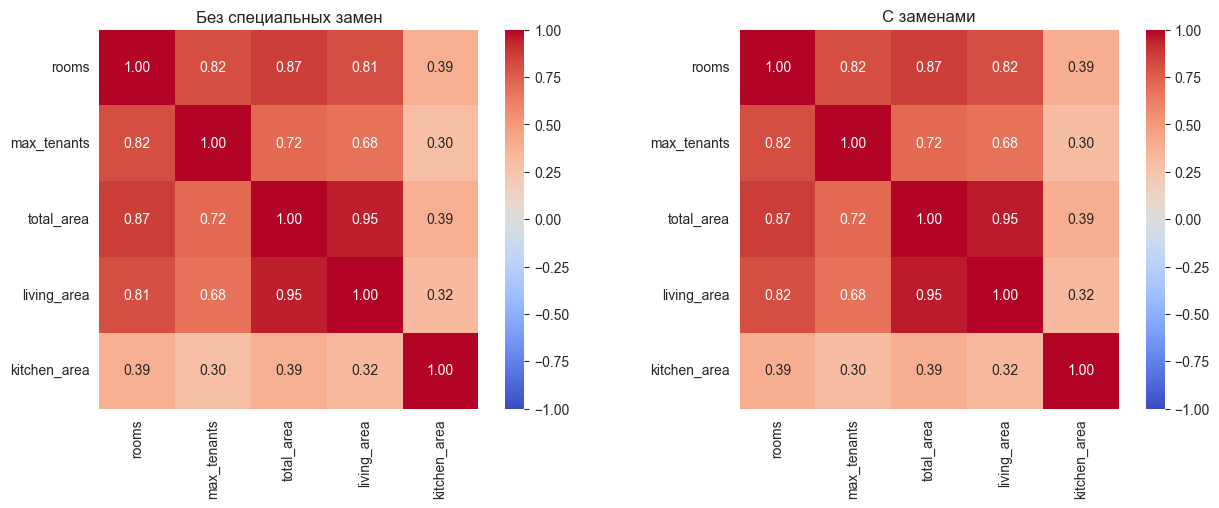

,rooms,max_tenants,total_area,living_area,kitchen_area
Δ абсолютной корреляции,,,,,
rooms,0.000,-0.002,0.000,0.005,0.005
max_tenants,-0.002,0.000,-0.001,0.000,0.003
total_area,0.000,-0.001,0.000,0.004,0.006
living_area,0.005,0.000,0.004,0.000,0.007
kitchen_area,0.005,0.003,0.006,0.007,0.000


In [37]:
datasets = {
    "Без специальных замен": X_without[COLS].astype(float),
    "С заменами": X_with[COLS].astype(float),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, data) in zip(axes, datasets.items()):
    sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title(name)

plt.tight_layout()
plt.show()

# Изменение абсолютной силы линейной связи
corr_before = datasets["Без специальных замен"].corr()
corr_after = datasets["С заменами"].corr()
display((corr_after.abs() - corr_before.abs()).round(3).rename_axis("Δ абсолютной корреляции"))

Вывод: изменения корреляции <= 0.007, заполнение не исказило структуру данных

### 4.6.4 VIF для 5 признаков с поочередном их удалением

Без специальных замен: 7673 строк для VIF
С заменами: 8499 строк для VIF


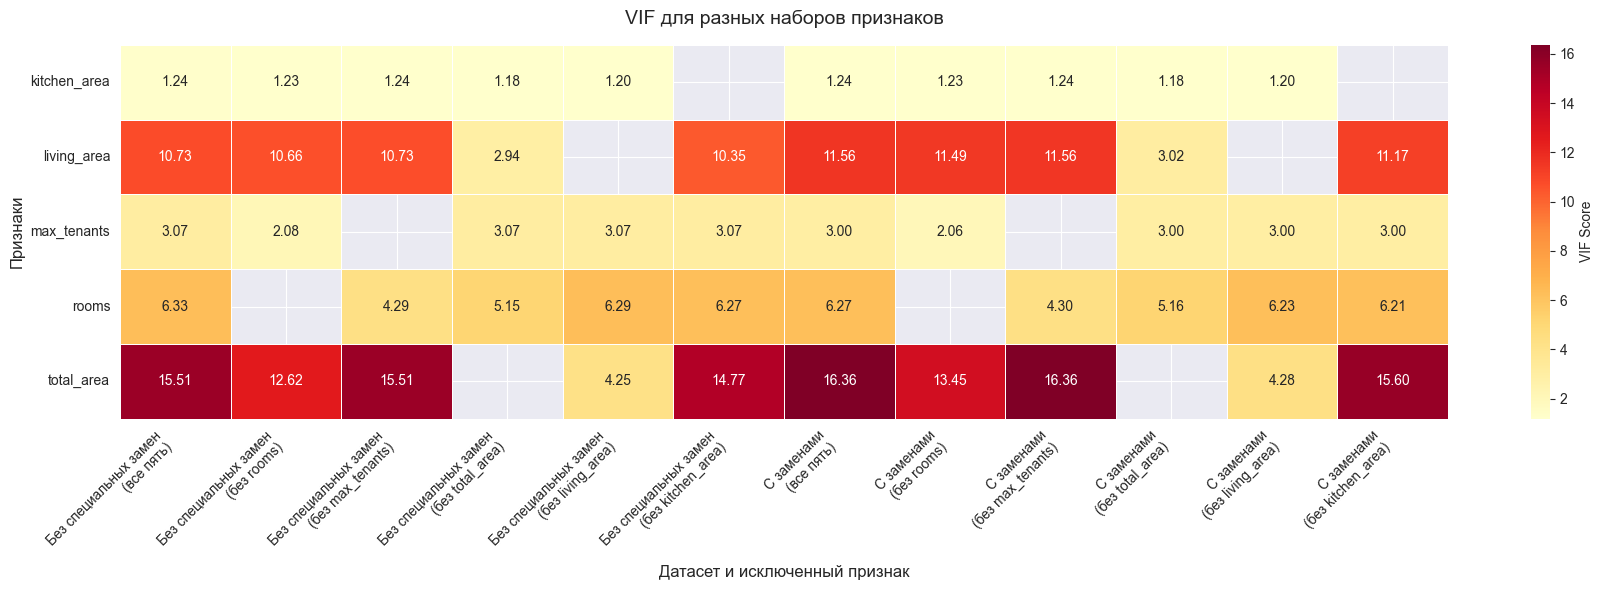

In [38]:
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    matrix = add_constant(data.astype(float), has_constant="add")
    return pd.Series([variance_inflation_factor(matrix.to_numpy(), i) for i in range(1, matrix.shape[1])], index=data.columns)

vif_results = {}

for name, data in datasets.items():
    complete = data.dropna()
    print(f"{name}: {len(complete)} строк для VIF")

    vif_results[(name, "все пять")] = calculate_vif(complete)

    # Каждый раз исключаем один признак из исходных пяти
    for col in COLS:
        vif_results[(name, f"без {col}")] = calculate_vif(complete.drop(columns=col))

vif_table = pd.DataFrame(vif_results)

heatmap_columns = [f"{ds}\n({subset})" for ds, subset in vif_table.columns]
vif_table.columns = heatmap_columns
plt.figure(figsize=(max(12, len(vif_table.columns) * 1.5), 6))

sns.heatmap(vif_table,  annot=True, cmap="YlOrRd",  fmt=".2f", cbar_kws={'label': 'VIF Score'}, linewidths=.5, linecolor='white')

plt.title("VIF для разных наборов признаков", fontsize=14, pad=15)
plt.ylabel("Признаки", fontsize=12)
plt.xlabel("Датасет и исключенный признак", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Вывод: 
- на полной выборке VIF для total_area и living_area очень высокий => мультиколлинеарность. Удаление одного из них снижает Vif
- также видно, что замены в среднем немного подняли значения VIF для total_area и living_area, из-за того, что площади заполнялись линейно функцией(долей)
Решение: пока не будет делать точных выводов и удалять один из столбцов, посмотрим как себя ведут линейная модель

Модели на разных наборах признаков

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

# Исходная пятёрка, исключение каждого столбца и компактный вариант
feature_sets = {"все пять": COLS.copy()}
for col in COLS:
    feature_sets[f"без {col}"] = [c for c in COLS if c != col]
feature_sets["площадь, комнаты и кухня"] = ["total_area", "rooms", "kitchen_area"]

preparations = {"базовая медиана": base_pipeline, "доли и подбор жильцов": filled_pipeline}
models = {"LinearRegression": LinearRegression(), "Ridge": Ridge(alpha=10)}

cv = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train))
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}
rows = []

for prep_name, preparation in preparations.items():
    for model_name, model in models.items():
        for set_name, cols in feature_sets.items():
            pipe = Pipeline([
                ("preparation", clone(preparation)),
                ("select", ColumnTransformer([("features", "passthrough", cols)], remainder="drop")),
                ("remaining", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("model", clone(model)),
            ])

            # В CV передаём исходные данные, не X_with и не X_without
            scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
            mae = -scores["test_MAE"]
            rmse = -scores["test_RMSE"]
            rows.append([prep_name, model_name, set_name, len(cols), mae.mean(), mae.std(), rmse.mean()])

results = pd.DataFrame(rows, columns=["заполнение", "модель", "набор", "признаков", "MAE", "MAE std", "RMSE"])

# Dummy показывает, полезнее ли модель простого прогноза медианной цены
dummy = cross_validate(DummyRegressor(strategy="median"), np.zeros((len(y_train), 1)), y_train, cv=cv, scoring=scoring)
dummy_mae = -dummy["test_MAE"].mean()

results["ΔMAE к Dummy"] = results["MAE"] - dummy_mae
print("Dummy MAE:", round(dummy_mae, 2))
display(results.sort_values("MAE").round(2))

Dummy MAE: 22743.74


,заполнение,модель,набор,признаков,MAE,MAE std,RMSE,ΔMAE к Dummy
6,базовая медиана,LinearRegression,"площадь, комнаты и кухня",3,25817.85,702.19,111472.10,3074.11
2,базовая медиана,LinearRegression,без max_tenants,4,25818.57,703.95,111473.93,3074.83
4,базовая медиана,LinearRegression,без living_area,4,25819.59,703.86,111499.08,3075.86
0,базовая медиана,LinearRegression,все пять,5,25820.30,705.44,111501.24,3076.56
13,базовая медиана,Ridge,"площадь, комнаты и кухня",3,25821.79,703.53,111471.88,3078.05
9,базовая медиана,Ridge,без max_tenants,4,25821.86,705.79,111473.74,3078.12
18,доли и подбор жильцов,LinearRegression,без living_area,4,25823.41,704.33,111502.48,3079.67
11,базовая медиана,Ridge,без living_area,4,25823.45,705.14,111498.68,3079.71
7,базовая медиана,Ridge,все пять,5,25823.59,707.28,111500.86,3079.85
14,доли и подбор жильцов,LinearRegression,все пять,5,25826.89,704.15,111508.52,3083.15


Вывод: ΔMAE к Dummy показывает ошибку больше, чем 3000, по сравнению со средним все цены завышены, что говорит о том, что регрессия и Ridge хуже простого предположения средней цены.

In [40]:
# Сравниваем одинаковые модели и наборы при двух способах заполнения
comparison = results.pivot(index=["модель", "набор"], columns="заполнение", values="MAE")
comparison["ΔMAE специальных замен"] = comparison["доли и подбор жильцов"] - comparison["базовая медиана"]
display(comparison.sort_values("ΔMAE специальных замен").round(2))

# Лучший вариант для каждой модели и способа заполнения
best = results.groupby(["заполнение", "модель"])["MAE"].idxmin()
display(results.loc[best].sort_values("MAE").round(2))

заполнение                                 базовая медиана  \
модель           набор                                       
LinearRegression без total_area                   26223.77   
Ridge            без total_area                   26224.90   
LinearRegression без kitchen_area                 25962.41   
Ridge            без kitchen_area                 25966.02   
LinearRegression без living_area                  25819.59   
Ridge            без living_area                  25823.45   
                 все пять                         25823.59   
LinearRegression все пять                         25820.30   
                 площадь, комнаты и кухня         25817.85   
Ridge            площадь, комнаты и кухня         25821.79   
LinearRegression без max_tenants                  25818.57   
Ridge            без max_tenants                  25821.86   
                 без rooms                        25902.17   
LinearRegression без rooms                        25900.77   

заполнение                                 доли и подбор жильцов  \
модель           набор                                             
LinearRegression без total_area                         26078.01   
Ridge            без total_area                         26080.06   
LinearRegression без kitchen_area                       25947.87   
Ridge            без kitchen_area                       25951.83   
LinearRegression без living_area                        25823.41   
Ridge            без living_area                        25827.37   
                 все пять                               25830.15   
LinearRegression все пять                               25826.89   
                 площадь, комнаты и кухня               25828.66   
Ridge            площадь, комнаты и кухня               25832.61   
LinearRegression без max_tenants                        25830.82   
Ridge            без max_tenants                        25834.13   
                 без rooms                              25921.24   
LinearRegression без rooms                              25919.99   

заполнение                                 ΔMAE специальных замен  
модель           набор                                             
LinearRegression без total_area                           -145.75  
Ridge            без total_area                           -144.85  
LinearRegression без kitchen_area                          -14.53  
Ridge            без kitchen_area                          -14.19  
LinearRegression без living_area                             3.81  
Ridge            без living_area                             3.92  
                 все пять                                    6.57  
LinearRegression все пять                                    6.59  
                 площадь, комнаты и кухня                   10.81  
Ridge            площадь, комнаты и кухня                   10.82  
LinearRegression без max_tenants                            12.25  
Ridge            без max_tenants                            12.26  
                 без rooms                                  19.06  
LinearRegression без rooms                                  19.22

,заполнение,модель,набор,признаков,MAE,MAE std,RMSE,ΔMAE к Dummy
6,базовая медиана,LinearRegression,"площадь, комнаты и кухня",3,25817.85,702.19,111472.10,3074.11
13,базовая медиана,Ridge,"площадь, комнаты и кухня",3,25821.79,703.53,111471.88,3078.05
18,доли и подбор жильцов,LinearRegression,без living_area,4,25823.41,704.33,111502.48,3079.67
25,доли и подбор жильцов,Ridge,без living_area,4,25827.37,705.56,111502.07,3083.63
